# KinaSPire toy example

This notebook walks through the full KinaSPire pipeline on a small simulated phosphoproteomics dataset, including 4 steps:

1. Data preprocessing
2. Model training
3. Kinase activity extraction
4. Visualization against ground-truth activity

The example files are in `examples/example_data/`:

| File | Description |
| --- | --- |
| `toy_phosphoproteome.feather` | Phosphosites × samples (20 phosphosites, 600 samples) |
| `toy_prior.tsv` | Phosphosites × kinase prior |
| `toy_metadata.tsv` | Sample metadata and simulated true kinase activity |

## Environment and paths

Open this notebook from `KinaSPire/examples/`, or make sure the working directory can resolve the package root. The next cell adds `kinaspire` to `sys.path`.

Training hyperparameters are in `configs/toy.yaml`. If you do not have a GPU, set `runtime.device` to `cpu`.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import torch

# Resolve the package root from examples/, the package directory, or the parent git repo
cwd = Path.cwd().resolve()
candidates = [cwd, cwd.parent, cwd / "KinaSPire", cwd.parent / "KinaSPire"]
ROOT = next((p for p in candidates if (p / "kinaspire").is_dir()), cwd.parent)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

DATA_DIR = ROOT / "examples" / "example_data"
CONFIG_PATH = ROOT / "configs" / "toy.yaml"
OUTPUT_DIR = ROOT / "examples" / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# print("package root:", ROOT)
# print("config:", CONFIG_PATH)
# print("output:", OUTPUT_DIR)

## Step 1. Data preprocessing

`DataProcessor` does three things:

1. Load the phosphosite matrix (phosphosites × samples) and the KSR prior (phosphosites × kinases)
2. Apply `RobustMinScaler` per phosphosite and shift the minimum to 0
3. Transpose the prior to kinases × phosphosites, drop kinases with no substrates, and save parquet files

Outputs:

- `processed_data/data.parquet`: samples × phosphosites
- `processed_data/prior.parquet`: kinases × phosphosites

In [ ]:
from kinaspire.preprocessing import DataProcessor

data_pp = DataProcessor(
    exp_path=str(DATA_DIR / "toy_phosphoproteome.feather"),
    ksr_path=str(DATA_DIR / "toy_prior.tsv"),
    output_path=str(OUTPUT_DIR),
    with_centering=False,
    quantile_range=(1, 99),
    unit_variance=False,
)
data, prior = data_pp.process_all()

Inspect the processed matrices below. `fit_model` expects `data` as **samples × phosphosites** and `prior` as **kinases × phosphosites**, with matching site columns.


In [3]:
site_order = [f"p{i}" for i in range(1, 6)] + [f"q{i}" for i in range(1, 6)] + [f"r{i}" for i in range(1, 8)] + [f"n{i}" for i in range(1, 4)]

data = pd.read_parquet(OUTPUT_DIR / "processed_data" / "data.parquet")
prior = pd.read_parquet(OUTPUT_DIR / "processed_data" / "prior.parquet")

data = data.reindex(columns=site_order)
prior = prior.reindex(columns=site_order)

print("data (sample × site):", data.shape)
print("prior (kinase × site):", prior.shape)
display(data.head())
display(prior)

data (sample × site): (600, 20)
prior (kinase × site): (3, 20)


,p1,p2,p3,p4,p5,q1,q2,q3,q4,q5,r1,r2,r3,r4,r5,r6,r7,n1,n2,n3
S1,0.943717,0.914977,0.736396,0.556312,0.577805,0.637483,0.451644,0.601672,0.474070,0.551624,0.570284,0.823659,0.470605,0.625419,0.727232,0.570279,0.549610,0.771868,0.882059,0.726773
S2,0.791548,0.836656,0.635620,0.854663,0.984683,0.832264,0.782035,0.696416,0.890637,0.813027,0.732638,0.947681,0.581400,0.806807,0.820204,0.714519,0.813062,0.934195,0.877673,0.954528
S3,0.643240,0.618536,0.543664,0.549125,0.654287,0.507311,0.529236,0.522466,0.611998,0.691046,0.825945,0.944405,0.693666,0.902731,0.833893,0.887234,1.035064,0.684403,0.759973,0.663040
S4,0.851369,0.949206,0.775052,0.475332,0.514484,0.613131,0.663856,0.597328,0.458472,0.584641,0.987638,1.319459,1.111943,1.198912,1.271249,1.218300,1.225367,0.328192,0.833977,0.991358
S5,0.361185,0.329374,0.291659,0.681704,0.706043,0.629339,0.607090,0.688284,0.695725,0.746098,0.347466,0.448540,0.189067,0.471874,0.339786,0.366827,0.395220,0.581630,0.581370,0.511491


,p1,p2,p3,p4,p5,q1,q2,q3,q4,q5,r1,r2,r3,r4,r5,r6,r7,n1,n2,n3
K1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
K2,0,0,0,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0
K3,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,0,0,0


## Step 2. Train KinaSPire

`fit_model` reads hyperparameters from YAML. Outputs go to `examples/outputs/toy_example/`, including models, `performance.csv`, and the resolved `config.yaml`

Full training takes a while.

In [ ]:
from kinaspire.training import fit_model

fit_model(
    data, prior,
    config=str(CONFIG_PATH),
    output_path=str(OUTPUT_DIR / "toy_example"),
)

## Step 3. Extract kinase activity

You can inspect `performance.csv` and pick a model by validation R². Then extract per-sample kinase activity from the encoder (`model.prior`).

In [6]:
perf = pd.read_csv(OUTPUT_DIR / "toy_example" / "performance.csv")
perf = perf.sort_values("val_r2", ascending=False)
perf.head()

,cv,weight_decay,refit,train_loss,val_loss,val_r2,activation,drop_p_prior,drop_p_kki,drop_p_ksr
4,0,1.000000e-10,3.0,0.014546,0.011135,0.814262,ReLU0,0.05,0.0,0.0
3,0,1.000000e-10,2.0,0.014816,0.011105,0.784261,ReLU0,0.05,0.0,0.0
2,0,1.000000e-10,1.0,0.015529,0.011814,0.770224,ReLU0,0.05,0.0,0.0
5,0,1.000000e-10,4.0,0.014876,0.011600,0.766832,ReLU0,0.05,0.0,0.0
1,0,1.000000e-10,0.0,0.016890,0.014670,0.734158,ReLU0,0.05,0.0,0.0


In [7]:
from kinaspire.activity import cal_kin_act, split_cols, scale_kin_act

best = perf.iloc[0]
cv = int(best["cv"])
wd = best["weight_decay"]
refit = best["refit"]
refit_tag = "None" if pd.isna(refit) else str(int(refit))
model_path = OUTPUT_DIR / "toy_example" / "model" / f"cv{cv}_wd{wd}_refit{refit_tag}.pth"
# print("selected model:", model_path)

model = torch.load(model_path, weights_only=False, map_location="cpu")

kin_act = cal_kin_act(data=data, prior=prior, model=model, batch_size=64, meta_kin=False, device="cpu")
kin_act = split_cols(kin_act)  # sample × kinase
kin_act = kin_act.T            # kinase × sample
kin_act_scaled = scale_kin_act(kin_act, prior)

kin_act_scaled

,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10,...,S591,S592,S593,S594,S595,S596,S597,S598,S599,S600
K1,0.727359,0.625730,0.493674,0.724019,0.246455,0.759838,0.422063,0.677686,0.670394,0.238150,...,0.467511,0.293976,0.615065,0.601580,0.454026,0.833323,0.592033,0.734428,0.407923,0.388710
K2,0.425678,0.687856,0.452176,0.436531,0.544218,0.729562,0.816714,0.695326,0.333181,0.140020,...,0.389891,0.621159,0.280649,0.661669,0.506479,0.908869,0.874206,0.390130,0.402328,0.708719
K3,0.476403,0.602806,0.686578,0.943528,0.270060,0.718299,0.776429,0.288540,0.357368,0.374046,...,0.658479,0.592257,0.584021,0.617142,0.493915,0.661765,0.628849,0.605683,0.696433,0.407487


In [8]:
kin_act_scaled.to_csv(OUTPUT_DIR / "toy_example" / "kinaspire_act.csv")

## Step 4. Visualization

Compare against true activity in `toy_metadata.tsv`: first compute correlations for K1 / K2 / K3, then plot true and inferred activity heatmaps ordered by K1/K2 state.

In [9]:
meta = pd.read_csv(DATA_DIR / "toy_metadata.tsv", sep="\t", index_col=0)
meta["State"] = meta["K1_state"].astype(str) + meta["K2_state"].astype(str)
meta.head()

,K1,K2,K3,K1_state,K2_state,State
S1,1.506136,0.153239,-0.245984,1,0,10
S2,0.595712,0.774734,-0.195310,0,0,00
S3,0.561443,0.255747,0.384849,0,0,00
S4,1.811136,0.081657,2.380448,1,0,10
S5,-0.094456,1.180077,-1.235073,0,1,01


In [10]:
from scipy.stats import spearmanr, pearsonr

activity = kin_act_scaled.copy().T
activity = activity.loc[meta.index]

corr_results = []
for kinase in ["K1", "K2", "K3"]:
    rho, rho_p = spearmanr(activity[kinase], meta[kinase])
    r, r_p = pearsonr(activity[kinase], meta[kinase])
    corr_results.append({
        "kinase": kinase,
        "spearman_rho": rho,
        "spearman_p": rho_p,
        "pearson_r": r,
        "pearson_p": r_p,
    })

corr_df = pd.DataFrame(corr_results)
corr_df

,kinase,spearman_rho,spearman_p,pearson_r,pearson_p
0,K1,0.960887,0.000000e+00,0.943190,2.392604e-288
1,K2,0.974804,0.000000e+00,0.957938,0.000000e+00
2,K3,0.949703,9.929021e-304,0.956820,4.940656e-323


In [11]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

def plot_kinase_activity_heatmap(
    kin_act_df_scaled,
    true_activity,
    state_order=("00", "10", "01", "11"),
    kinase_red="#D9534F",
    figsize=(8, 2.5),
    colorbar_label="Kinase activity",
    vmin=0,
    vmax=1,
):
    """Plot a kinase-activity heatmap with samples ordered by K1/K2 state."""
    set3_colors = sns.color_palette("Set3", 12).as_hex()
    set2_colors = sns.color_palette("Set2", 8).as_hex()
    background_colors = (
        [set3_colors[0], set3_colors[2], set3_colors[4], set3_colors[5], set3_colors[6]]
        + [set2_colors[2], set2_colors[7]]
    )
    state_colors = {
        "00": background_colors[-1],
        "10": kinase_red,
        "01": background_colors[0],
        "11": background_colors[1],
    }

    state_info = true_activity[["State"]].copy()
    state_info["State"] = pd.Categorical(state_info["State"], categories=list(state_order), ordered=True)
    state_info = state_info.sort_values(by="State", kind="stable")
    ordered_samples = state_info.index

    missing_samples = ordered_samples.difference(kin_act_df_scaled.columns)
    if len(missing_samples) > 0:
        raise ValueError(f"kin_act_df_scaled is missing samples: {missing_samples.tolist()}")

    plot_data = kin_act_df_scaled.loc[:, ordered_samples].copy()
    state_values = state_info.loc[ordered_samples, "State"].astype(str).to_numpy()
    n_samples = len(ordered_samples)
    group_boundaries = np.where(state_values[:-1] != state_values[1:])[0] + 1
    state_to_code = {state: i for i, state in enumerate(state_order)}
    state_codes = np.array([state_to_code[state] for state in state_values])[np.newaxis, :]
    state_cmap = ListedColormap([state_colors[state] for state in state_order])

    plt.style.use("default")
    mpl.rcParams["pdf.fonttype"] = 42
    mpl.rcParams["ps.fonttype"] = 42

    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(
        nrows=2, ncols=2, height_ratios=[0.10, 1], width_ratios=[1, 0.025], hspace=0.035, wspace=0.08
    )
    ax_anno = fig.add_subplot(gs[0, 0])
    ax_heatmap = fig.add_subplot(gs[1, 0], sharex=ax_anno)
    ax_cbar = fig.add_subplot(gs[1, 1])
    fig.add_subplot(gs[0, 1]).axis("off")

    ax_anno.pcolormesh(
        np.arange(n_samples + 1), np.array([0, 1]), state_codes,
        cmap=state_cmap, vmin=-0.5, vmax=len(state_order) - 0.5, shading="flat",
    )
    ax_anno.set_xlim(0, n_samples)
    ax_anno.set_ylim(0, 1)
    ax_anno.set_xticks([])
    ax_anno.set_yticks([])
    ax_anno.set_ylabel("State", rotation=0, ha="right", va="center", labelpad=10)
    for spine in ax_anno.spines.values():
        spine.set_visible(False)

    sns.heatmap(
        plot_data,
        cmap="vlag",
        center=(vmin + vmax) / 2 if vmin is not None and vmax is not None else 0.5,
        vmin=vmin,
        vmax=vmax,
        xticklabels=False,
        yticklabels=True,
        cbar=True,
        cbar_ax=ax_cbar,
        cbar_kws={"label": colorbar_label},
        ax=ax_heatmap,
    )
    ax_heatmap.set_xlim(0, n_samples)
    ax_heatmap.tick_params(axis="x", which="both", bottom=False, top=False, length=0)
    ax_heatmap.set_xlabel("Samples")
    ax_heatmap.set_ylabel("Kinases")

    for pos in group_boundaries:
        ax_anno.axvline(pos, color="white", linewidth=1)

    legend_handles = [
        Patch(facecolor=state_colors[state], edgecolor="none", label=state) for state in state_order
    ]
    fig.legend(
        handles=legend_handles, title="K1/K2 state", ncol=4, frameon=False,
        loc="upper left", bbox_to_anchor=(0.10, 1.04), borderaxespad=0,
        handlelength=1.2, columnspacing=1.2,
    )
    fig.subplots_adjust(left=0.10, right=0.94, bottom=0.18, top=0.78)
    plt.show()

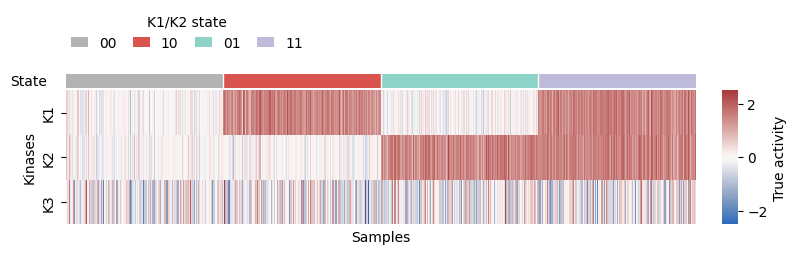

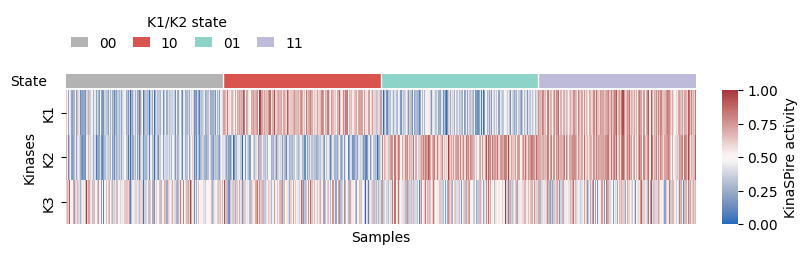

In [12]:
plot_kinase_activity_heatmap(
    meta[["K1", "K2", "K3"]].T, meta, vmin=-2.5, vmax=2.5, colorbar_label="True activity"
)
plot_kinase_activity_heatmap(
    activity.T, meta, vmin=0, vmax=1, colorbar_label="KinaSPire activity"
)